# Three-Dimensional Plots

Anatomy and dynamics are often three-dimensional. These functions draw with Matplotlib's `mplot3d` toolkit and return the 3-D axes (pass `ax=fig.add_subplot(..., projection='3d')` to place several in one figure; `ax.view_init(elev, azim)` sets the viewing angle):

| Function | Shows |
|---|---|
| `trajectory_3d`, `phase_space_3d` | trajectories through a 3-D state space |
| `neural_network_3d` | a layered network with weights and activations |
| `connectivity_3d` | connections between two populations at their positions |
| `electrode_array_3d` | electrode positions colored and sized by signal |
| `dendrite_tree_3d` | a neuron's morphology as line segments |
| `brain_surface_3d` | a triangulated surface colored by values |
| `volume_rendering` | voxels of a 3-D array above a threshold |

For rotating figures interactively, use the Plotly functions of the previous notebook.

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import braintools

plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(5)

## 2. Trajectories in State Space

`trajectory_3d` takes a `(time, 3)` array; `phase_space_3d` takes three separate state variables. Both color the path by time. The Lorenz system, integrated with RK4, and the population state of a simulated network projected on its first three principal components:

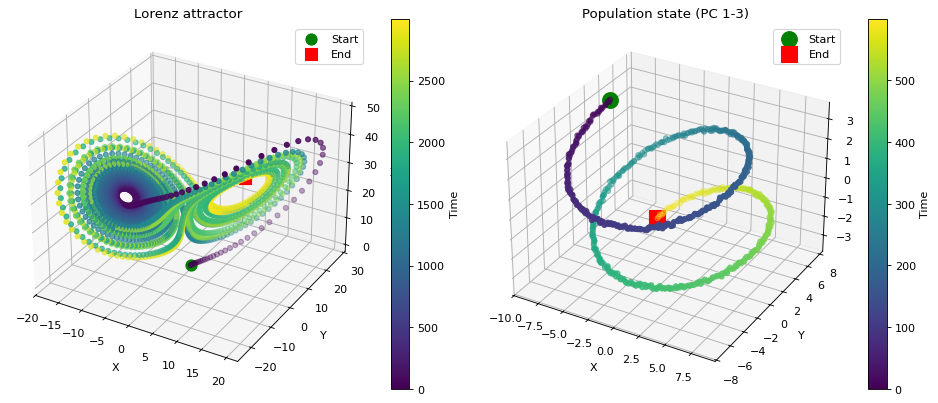

In [2]:
def lorenz(s, sigma=10.0, rho=28.0, beta=8 / 3):
    x, y, z = s
    return np.array([sigma * (y - x), x * (rho - z) - y, x * y - beta * z])

dt, n = 0.01, 3000
s = np.zeros((n, 3)); s[0] = (1.0, 1.0, 1.0)
for k in range(1, n):
    a = lorenz(s[k - 1]); b = lorenz(s[k - 1] + dt / 2 * a); c = lorenz(s[k - 1] + dt / 2 * b); d = lorenz(s[k - 1] + dt * c)
    s[k] = s[k - 1] + dt / 6 * (a + 2 * b + 2 * c + d)

# population: 60 neurons mixing a slow rotation and a drift, plus noise; PCA by SVD
t = np.linspace(0, 4 * np.pi, 600)
latent = np.c_[np.cos(t), np.sin(t), t / (4 * np.pi)]
rates = latent @ rng.normal(size=(3, 60)) + 0.05 * rng.normal(size=(600, 60))
c = rates - rates.mean(0)
pcs = c @ np.linalg.svd(c, full_matrices=False)[2][:3].T

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
braintools.visualize.phase_space_3d(s[:, 0], s[:, 1], s[:, 2], ax=ax1, title="Lorenz attractor")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
braintools.visualize.trajectory_3d(pcs, ax=ax2, title="Population state (PC 1-3)")
plt.tight_layout(); plt.show()

The population trajectory is a helix: a rotation in two components and a slow drift in the third, recovered from 60 noisy neurons.

## 3. Layered Networks

`neural_network_3d(layer_sizes, weights, activations)` arranges each layer on a ring, one layer above the other. `weights[i]` must have shape `(layer_sizes[i], layer_sizes[i + 1])` (a transposed matrix raises an error); connections with $|w| > 0.01$ are drawn red (positive) or blue (negative) with width $5|w|$. `activations[i]` colors the nodes of layer `i`. Below, a small feed-forward network with sparse random weights and the activations it produces for one input:

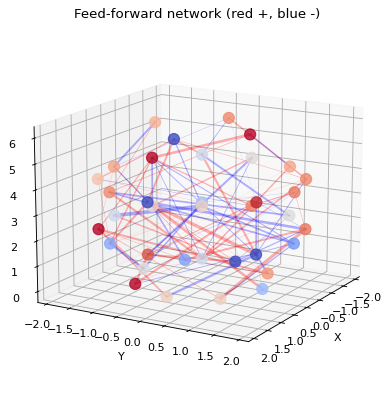

In [3]:
sizes = [8, 12, 12, 4]
weights = [rng.normal(0, 0.25, (m, n)) * (rng.random((m, n)) < 0.35) for m, n in zip(sizes[:-1], sizes[1:])]
acts = [rng.random(sizes[0])]
for Wl in weights:
    acts.append(np.tanh(acts[-1] @ Wl))

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
braintools.visualize.neural_network_3d(sizes, weights=weights, activations=acts, cmap="coolwarm", ax=ax,
                                       title="Feed-forward network (red +, blue -)")
ax.view_init(elev=15, azim=30)
plt.show()

## 4. Connections Between Populations

`connectivity_3d` draws two populations at their positions and the connections between them, given as a `(n_source, n_target)` matrix or as a list of `(source, target)` index pairs; `connection_strengths` sets the line widths. Here a thalamic population (bottom) projects to a cortical sheet (top), each thalamic neuron targeting the cortical neurons closest to it in the horizontal plane:

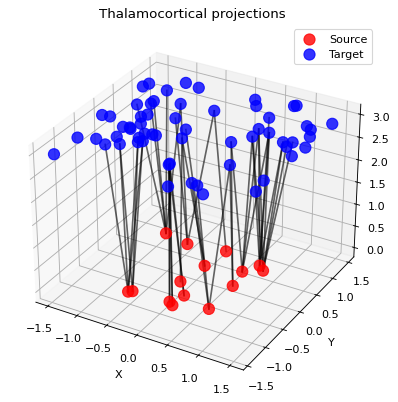

45 connections, 3.0 targets per thalamic neuron on average


In [4]:
thal = np.c_[rng.uniform(-1, 1, (15, 2)), np.zeros(15)]
ctx = np.c_[rng.uniform(-1.5, 1.5, (60, 2)), np.full(60, 3.0)]
dist = np.linalg.norm(thal[:, None, :2] - ctx[None, :, :2], axis=-1)
conn = dist < 0.45                                           # (15, 60) boolean matrix
pairs = np.argwhere(conn)
strength = np.exp(-dist[conn] / 0.3)

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
braintools.visualize.connectivity_3d(thal, ctx, pairs, connection_strengths=2 * strength, ax=ax,
                                     connection_format="pairs", title="Thalamocortical projections")
plt.show()
print(f"{len(pairs)} connections, {conn.sum(1).mean():.1f} targets per thalamic neuron on average")

## 5. Electrode Arrays

`electrode_array_3d` places electrodes at their 3-D positions. With `signals` (one value per electrode, or a time series per electrode, which is reduced to its norm), electrodes are colored by signal magnitude and their marker area grows with it: $10 + 90 \cdot$ `signal_scale` $\cdot\, |s| / \max|s|$. A 10 × 10 Utah-style array with a local activity hotspot:

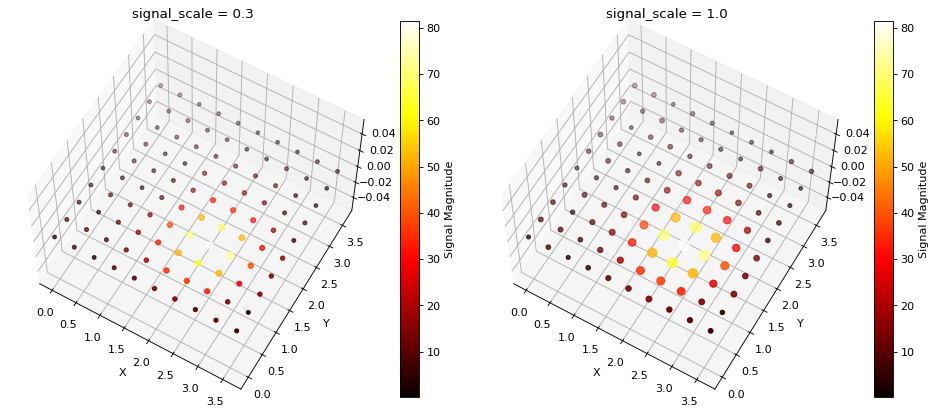

In [5]:
gx, gy = np.meshgrid(np.arange(10) * 0.4, np.arange(10) * 0.4)
positions = np.c_[gx.ravel(), gy.ravel(), np.zeros(100)]                     # mm
amplitude = 80 * np.exp(-((gx - 2.4) ** 2 + (gy - 1.2) ** 2).ravel() / (2 * 0.6 ** 2)) + rng.uniform(0, 8, 100)   # uV

fig = plt.figure(figsize=(12, 5))
for i, scale in enumerate([0.3, 1.0]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    braintools.visualize.electrode_array_3d(positions, signals=amplitude, signal_scale=scale, ax=ax,
                                            title=f"signal_scale = {scale}")
    ax.view_init(elev=60, azim=-60)
plt.tight_layout(); plt.show()

## 6. Dendritic Morphology

`dendrite_tree_3d` draws a morphology given as a list of `(start, end)` segments, with optional `colors` and `diameters`, drawn as line widths of 10 × diameter points (so scale physical diameters to a few tenths). A randomly branching tree whose segments taper by 30 % at each branch point:

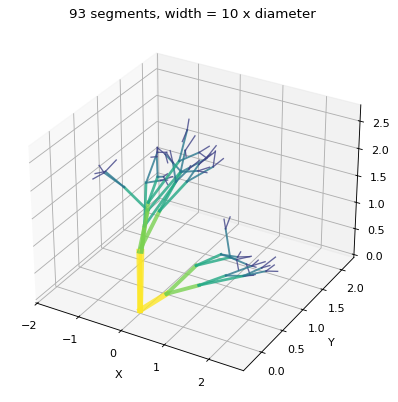

In [6]:
segments, diameters, colors = [], [], []

def grow(start, direction, diameter, depth):
    if depth == 0:
        return
    end = start + direction * rng.uniform(0.6, 1.0) * depth / 4
    segments.append((start, end)); diameters.append(diameter); colors.append(plt.cm.viridis(depth / 5))
    for _ in range(2):
        new_dir = direction + rng.normal(0, 0.5, 3)
        grow(end, new_dir / np.linalg.norm(new_dir), 0.7 * diameter, depth - 1)

for d in [(0, 0, 1), (0.8, 0, 0.6), (-0.6, 0.6, 0.5)]:
    grow(np.zeros(3), np.array(d) / np.linalg.norm(d), 0.5, 5)

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
braintools.visualize.dendrite_tree_3d(segments, diameters=diameters, colors=colors, ax=ax,
                                      title=f"{len(segments)} segments, width = 10 x diameter")
plt.show()

## 7. Surfaces

`brain_surface_3d(vertices, faces, values)` draws a triangulated surface; `values` (one per vertex) color the faces. An ellipsoid "hemisphere" built from a latitude–longitude grid, with an activity pattern centered on one region:

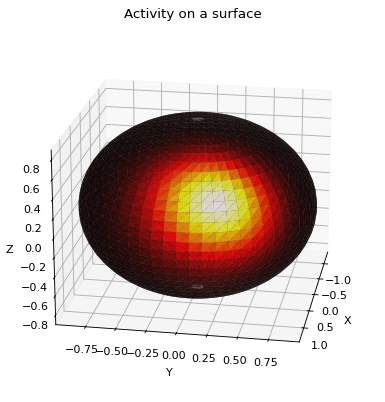

(1800, 3) (3480, 3)


In [7]:
n_lat, n_lon = 30, 60
lat, lon = np.meshgrid(np.linspace(0.05, np.pi - 0.05, n_lat), np.linspace(0, 2 * np.pi, n_lon, endpoint=False), indexing="ij")
vertices = np.c_[(1.4 * np.sin(lat) * np.cos(lon)).ravel(), (np.sin(lat) * np.sin(lon)).ravel(), (0.9 * np.cos(lat)).ravel()]
faces = []
for i in range(n_lat - 1):
    for j in range(n_lon):
        a, b = i * n_lon + j, i * n_lon + (j + 1) % n_lon
        c, d = a + n_lon, b + n_lon
        faces += [(a, b, c), (b, d, c)]
faces = np.array(faces)
center = np.array([1.2, 0.3, 0.4])
activity = np.exp(-np.sum((vertices - center) ** 2, axis=1) / (2 * 0.35 ** 2))

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
braintools.visualize.brain_surface_3d(vertices, faces, values=activity, cmap="hot", ax=ax, title="Activity on a surface")
ax.view_init(elev=20, azim=10)
plt.show()
print(vertices.shape, faces.shape)

## 8. Volumes

`volume_rendering(volume, threshold)` draws every voxel whose value exceeds the threshold, colored by value. Without a threshold it uses the midpoint of the data range, which also works for data that are negative or offset from zero, such as a signal change relative to baseline:

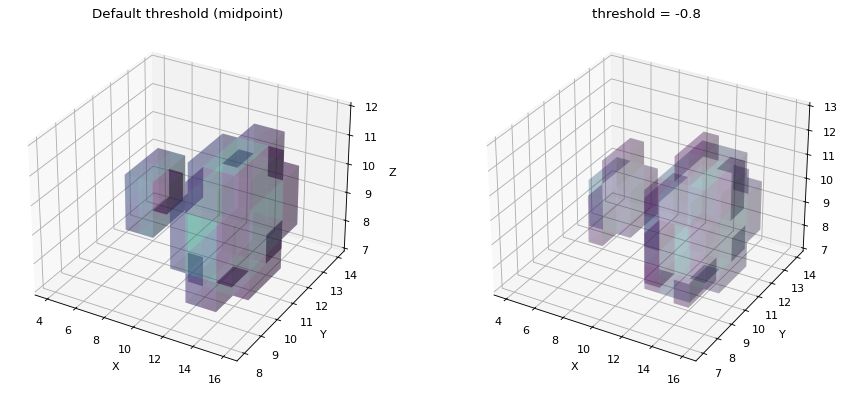

default threshold -0.74: 65 voxels; threshold -0.8: 88 voxels


In [8]:
g = np.linspace(-1, 1, 20)
X, Y, Z = np.meshgrid(g, g, g, indexing="ij")
blobs = np.exp(-((X - 0.4) ** 2 + Y ** 2 + Z ** 2) / 0.08) + 0.7 * np.exp(-((X + 0.5) ** 2 + (Y - 0.3) ** 2 + (Z + 0.2) ** 2) / 0.05)
signal_change = blobs - 1.2                       # all values negative: baseline -1.2, peaks near -0.2

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
braintools.visualize.volume_rendering(signal_change, ax=ax1, title="Default threshold (midpoint)")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
braintools.visualize.volume_rendering(signal_change, threshold=-0.8, alpha=0.2, ax=ax2, title="threshold = -0.8")
plt.tight_layout(); plt.show()
mid = signal_change.min() + (signal_change.max() - signal_change.min()) / 2
print(f"default threshold {mid:.2f}: {np.sum(signal_change > mid)} voxels; threshold -0.8: {np.sum(signal_change > -0.8)} voxels")

Both blobs exceed the default threshold; the lower threshold adds their flanks (88 instead of 65 voxels). Voxel plots grow expensive quickly (every voxel is a set of polygons); keep volumes to a few tens of voxels per side.

## Summary

- `trajectory_3d` / `phase_space_3d` show 3-D trajectories colored by time; for populations, project onto principal components first.
- `neural_network_3d` expects `weights[i]` of shape `(layer_sizes[i], layer_sizes[i + 1])`.
- `connectivity_3d` takes a connection matrix or index pairs (set `connection_format` when the shape is ambiguous).
- `electrode_array_3d` colors electrodes by signal and sizes them with `signal_scale`.
- `brain_surface_3d` colors a triangulated surface by per-vertex values; `volume_rendering` draws voxels above a threshold (default: midpoint of the data range).